# Modul 10 – Object Detection Method

In [1]:
import os
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve
import pickle
import random

try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as e:
    pass

def get_image_path(filename):
    candidates = [
        os.path.join('/content/drive/MyDrive/PCVK/Images', filename),
        os.path.join('/content/drive/MyDrive/Images', filename),
        os.path.join('/content/drive/MyDrive/5 Perkuliahan JTI/Materi Perkuliahan/MK PCVK/PCVK 2025/Images/facedet', filename),
        os.path.join('images', filename),
        os.path.join('images/facedet', filename),
        os.path.join('/content/images', filename),
        os.path.join('/content/images/facedet', filename),
        os.path.join('/content', filename),
        filename
    ]
    for path in candidates:
        if os.path.exists(path):
            return path
    return os.path.join('images', filename)

def get_cascade_path(filename):
    candidates = [
        os.path.join('images/haarcascades', filename),
        os.path.join('/content/drive/MyDrive/PCVK/Images/haarcascades', filename),
        os.path.join('/content/images/haarcascades', filename),
        os.path.join(cv.data.haarcascades, filename),
        filename
    ]
    for path in candidates:
        if os.path.exists(path):
            return path
    return os.path.join(cv.data.haarcascades, filename)

print("Environment setup & helper functions successfully initialized.")

Environment setup & helper functions successfully initialized.


---
## D1. Praktikum Deteksi Obyek Dasar
### 1. Inisialisasi dan Akses Direktori Citra
Memastikan seluruh citra praktikum dan pretrained Haar Cascades dapat diakses dengan baik di Google Drive maupun lokal.

In [2]:
required_images = [
    'cats_and_bunnies.jpg', 'cat2_templatejpg.jpg', 'bahrain.jpg', 
    'bahrain-template.jpg', 'car-park.jpg', 'chess-board.jpg', 
    'sudoku.jpg', 'laptop.jpg', 'pak_prabowo.jpeg'
]

print("Verifikasi file citra praktikum:")
for img_name in required_images:
    path = get_image_path(img_name)
    status = "OK" if os.path.exists(path) else "MISSING"
    print(f"  - {img_name:<25}: {status} ({path})")

Verifikasi file citra praktikum:
  - cats_and_bunnies.jpg     : OK (images/cats_and_bunnies.jpg)
  - cat2_templatejpg.jpg     : OK (images/cat2_templatejpg.jpg)
  - bahrain.jpg              : OK (images/bahrain.jpg)
  - bahrain-template.jpg     : OK (images/bahrain-template.jpg)
  - car-park.jpg             : OK (images/car-park.jpg)
  - chess-board.jpg          : OK (images/chess-board.jpg)
  - sudoku.jpg               : OK (images/sudoku.jpg)
  - laptop.jpg               : OK (images/laptop.jpg)
  - pak_prabowo.jpeg         : OK (pak_prabowo.jpeg)


### 2. Implementasi 6 Metode Template Matching pada OpenCV
Implementasikan 6 metode template matching pada OpenCV dengan menggunakan citra masukan `cats_and_bunnies.jpg` dan citra template `cat2_templatejpg.jpg`.

Keenam metode tersebut adalah:
1. `cv.TM_CCOEFF`
2. `cv.TM_CCOEFF_NORMED`
3. `cv.TM_CCORR`
4. `cv.TM_CCORR_NORMED`
5. `cv.TM_SQDIFF`
6. `cv.TM_SQDIFF_NORMED`

Untuk metode `TM_SQDIFF` dan `TM_SQDIFF_NORMED`, nilai kecocokan terbaik (titik terdeteksi) terletak pada nilai **minimum** (`min_loc`), sedangkan 4 metode lainnya terletak pada nilai **maksimum** (`max_loc`).

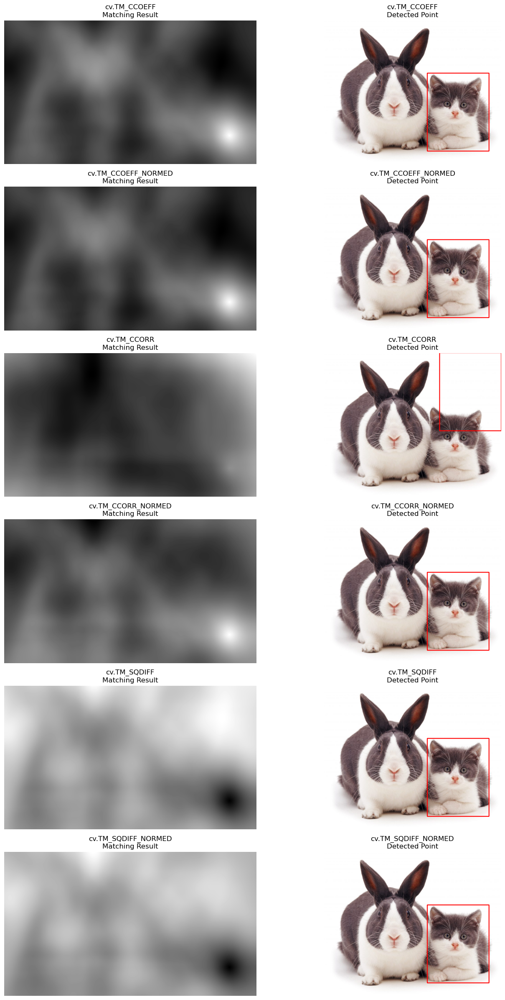

In [3]:
img = cv.imread(get_image_path('cats_and_bunnies.jpg'))
template = cv.imread(get_image_path('cat2_templatejpg.jpg'))

h, w = template.shape[:2]

methods = [
    'cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED',
    'cv.TM_CCORR', 'cv.TM_CCORR_NORMED',
    'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED'
]

plt.figure(figsize=(15, 24))

for i, meth_name in enumerate(methods):
    img_draw = img.copy()
    method = eval(meth_name)
    
    res = cv.matchTemplate(img, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)
    
    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc
        
    bottom_right = (top_left[0] + w, top_left[1] + h)
    
    cv.rectangle(img_draw, top_left, bottom_right, (0, 0, 255), 3)
    
    plt.subplot(6, 2, 2*i + 1)
    plt.imshow(res, cmap='gray')
    plt.title(f"{meth_name}\nMatching Result")
    plt.axis('off')
    
    plt.subplot(6, 2, 2*i + 2)
    plt.imshow(cv.cvtColor(img_draw, cv.COLOR_BGR2RGB))
    plt.title(f"{meth_name}\nDetected Point")
    plt.axis('off')

plt.tight_layout()
plt.show()

### 3. Template Matching Multi-Object Tanpa Library OpenCV
Implementasi konsep template matching untuk mendeteksi banyak objek (**multiple objects**) tanpa menggunakan library OpenCV (`cv.matchTemplate()`).
- Citra masukan: `bahrain.jpg`
- Citra template: `bahrain-template.jpg`

**Pendekatan Solusi**:
1. Menghitung **Normalized Cross-Correlation (NCC)** murni menggunakan NumPy dan Fast Fourier Transform (`scipy.signal.fftconvolve`).
2. Karena objek pulau tapal kuda di teluk Bahrain tersusun dalam berbagai orientasi/rotasi, pencocokan dilakukan secara multi-orientasi (rotasi template dari -120° hingga +150° dengan step 5°).
3. Menerapkan **Non-Maximum Suppression (NMS)** untuk menyaring deteksi tumpang tindih sehingga diperoleh tepat 6 kotak kuning di sekeliling pulau-pulau tersebut (sesuai gambar luaran modul pada halaman 25).

Total multiple objects terdeteksi: 6


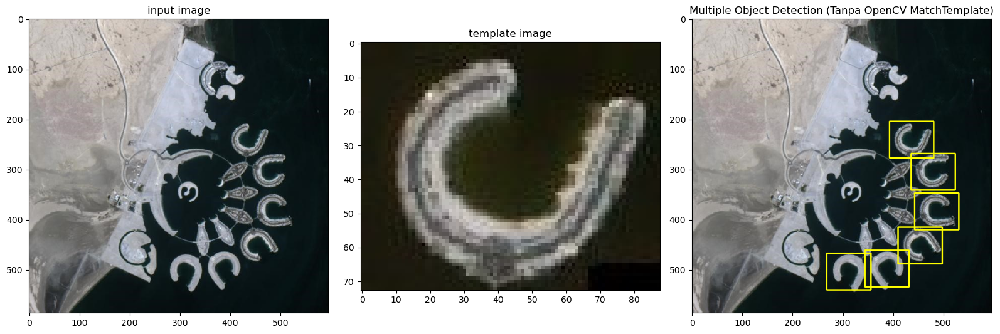

In [4]:
img_bahrain = cv.imread(get_image_path('bahrain.jpg'))
tmpl_bahrain = cv.imread(get_image_path('bahrain-template.jpg'))

img_gray = cv.cvtColor(img_bahrain, cv.COLOR_BGR2GRAY).astype(np.float32)
tmpl_gray = cv.cvtColor(tmpl_bahrain, cv.COLOR_BGR2GRAY).astype(np.float32)

all_boxes = []

for angle in range(-120, 150, 5):
    center = (tmpl_gray.shape[1] // 2, tmpl_gray.shape[0] // 2)
    M = cv.getRotationMatrix2D(center, angle, 1.0)
    rot_tmpl = cv.warpAffine(tmpl_gray, M, (tmpl_gray.shape[1], tmpl_gray.shape[0]))
    
    th, tw = rot_tmpl.shape
    tz = rot_tmpl - rot_tmpl.mean()
    t_sq = np.sum(tz**2)
    if t_sq < 1e-5:
        continue
    
    corr = fftconvolve(img_gray, tz[::-1, ::-1], mode='valid')
    ones = np.ones_like(rot_tmpl)
    img_sum = fftconvolve(img_gray, ones, mode='valid')
    img_sq = fftconvolve(img_gray**2, ones, mode='valid')
    var = np.maximum(img_sq - (img_sum**2) / (th * tw), 0)
    denom = np.sqrt(var * t_sq)
    denom[denom == 0] = 1e-10
    ncc = corr / denom
    
    loc = np.where(ncc >= 0.56)
    for pt in zip(*loc[::-1]):
        all_boxes.append([pt[0], pt[1], pt[0] + tw, pt[1] + th, ncc[pt[1], pt[0]]])

def apply_nms(boxes, overlap_thresh=0.15):
    if len(boxes) == 0:
        return []
    boxes = np.array(boxes)
    pick = []
    x1, y1, x2, y2, scores = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3], boxes[:, 4]
    area = (x2 - x1) * (y2 - y1)
    idxs = np.argsort(scores)
    
    while len(idxs) > 0:
        last = len(idxs) - 1
        i = idxs[last]
        pick.append(i)
        
        xx1 = np.maximum(x1[i], x1[idxs[:last]])
        yy1 = np.maximum(y1[i], y1[idxs[:last]])
        xx2 = np.minimum(x2[i], x2[idxs[:last]])
        yy2 = np.minimum(y2[i], y2[idxs[:last]])
        
        w = np.maximum(0, xx2 - xx1)
        h = np.maximum(0, yy2 - yy1)
        overlap = (w * h) / (area[i] + area[idxs[:last]] - (w * h))
        idxs = np.delete(idxs, np.concatenate(([last], np.where(overlap > overlap_thresh)[0])))
        
    return boxes[pick]

selected_boxes = apply_nms(all_boxes, overlap_thresh=0.15)
print(f"Total multiple objects terdeteksi: {len(selected_boxes)}")

img_res = img_bahrain.copy()
for b in selected_boxes:
    x1, y1, x2, y2 = b[:4].astype(int)
    cv.rectangle(img_res, (x1, y1), (x2, y2), (0, 255, 255), 2)

plt.figure(figsize=(16, 6))

plt.subplot(1, 3, 1)
plt.imshow(cv.cvtColor(img_bahrain, cv.COLOR_BGR2RGB))
plt.title("input image")

plt.subplot(1, 3, 2)
plt.imshow(tmpl_bahrain, cmap='gray')
plt.title("template image")

plt.subplot(1, 3, 3)
plt.imshow(cv.cvtColor(img_res, cv.COLOR_BGR2RGB))
plt.title("Multiple Object Detection (Tanpa OpenCV MatchTemplate)")

plt.tight_layout()
plt.show()

### 4. Implementasi Edge Detection pada OpenCV (Sobel, Canny, dan Laplacian)
Implementasikan metode Sobel Edge Detection, Canny Edge Detection, dan Laplacian Edge Detection pada OpenCV dengan menggunakan gambar `car-park.jpg`.
- a. **Sobel Edge Detection**: Berbasis turunan pertama terarah (X dan Y) lalu digabungkan dengan magnitude gradien.
- b. **Canny Edge Detection**: Detektor multi-tahap (penghilangan noise, kalkulasi gradien, non-maximum suppression, dan hysteresis thresholding).
- c. **Laplacian Edge Detection**: Berbasis turunan kedua spasial dengan Gaussian blur sebelumnya untuk menekan noise.

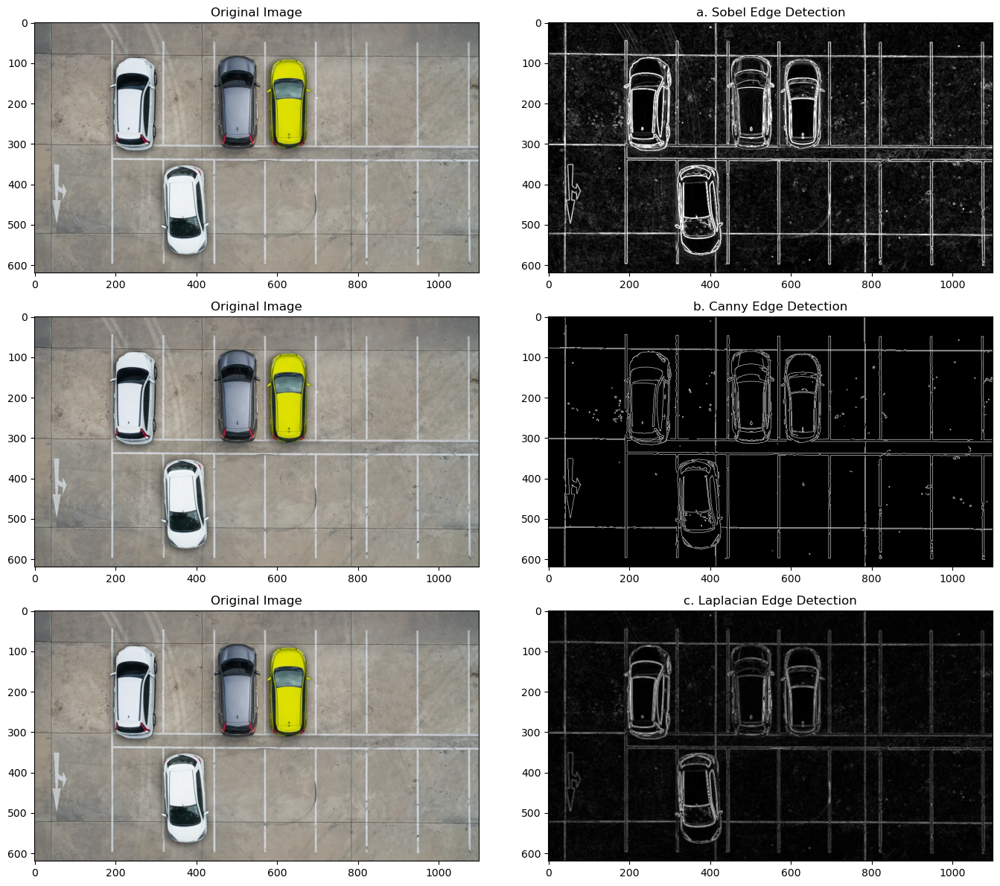

In [5]:
img_car = cv.imread(get_image_path('car-park.jpg'))
gray_car = cv.cvtColor(img_car, cv.COLOR_BGR2GRAY)

# a. Sobel Edge Detection
sobelx = cv.Sobel(gray_car, cv.CV_64F, 1, 0, ksize=3)
sobely = cv.Sobel(gray_car, cv.CV_64F, 0, 1, ksize=3)
sobel_mag = cv.magnitude(sobelx, sobely)
sobel_res = np.uint8(np.clip(sobel_mag, 0, 255))

# b. Canny Edge Detection
canny_res = cv.Canny(gray_car, threshold1=100, threshold2=200)

# c. Laplacian Edge Detection
blur_car = cv.GaussianBlur(gray_car, (3, 3), 0)
lap_res = cv.Laplacian(blur_car, cv.CV_64F, ksize=3)
lap_res = np.uint8(np.absolute(lap_res))

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

# 4a. Sobel
axes[0, 0].imshow(cv.cvtColor(img_car, cv.COLOR_BGR2RGB))
axes[0, 0].set_title("Original Image")
axes[0, 1].imshow(sobel_res, cmap='gray')
axes[0, 1].set_title("a. Sobel Edge Detection")

# 4b. Canny
axes[1, 0].imshow(cv.cvtColor(img_car, cv.COLOR_BGR2RGB))
axes[1, 0].set_title("Original Image")
axes[1, 1].imshow(canny_res, cmap='gray')
axes[1, 1].set_title("b. Canny Edge Detection")

# 4c. Laplacian
axes[2, 0].imshow(cv.cvtColor(img_car, cv.COLOR_BGR2RGB))
axes[2, 0].set_title("Original Image")
axes[2, 1].imshow(lap_res, cmap='gray')
axes[2, 1].set_title("c. Laplacian Edge Detection")

for ax_row in axes:
    for ax in ax_row:
        ax.set_xticks(np.arange(0, 1200, 200))
        ax.set_yticks(np.arange(0, 700, 100))

plt.tight_layout()
plt.show()

### 5. Implementasi Corner Detection pada OpenCV (Harris & Shi-Tomasi)
Menggunakan gambar `chess-board.jpg`:
- a. **Harris Corner Detection**: Mengevaluasi variasi intensitas ke berbagai arah. Titik sudut ditandai dengan warna merah.
- b. **Shi-Tomasi Detection**: Menggunakan kriteria $\min(\lambda_1, \lambda_2)$ dengan `cv.goodFeaturesToTrack()`. Titik sudut ditandai dengan lingkaran biru.

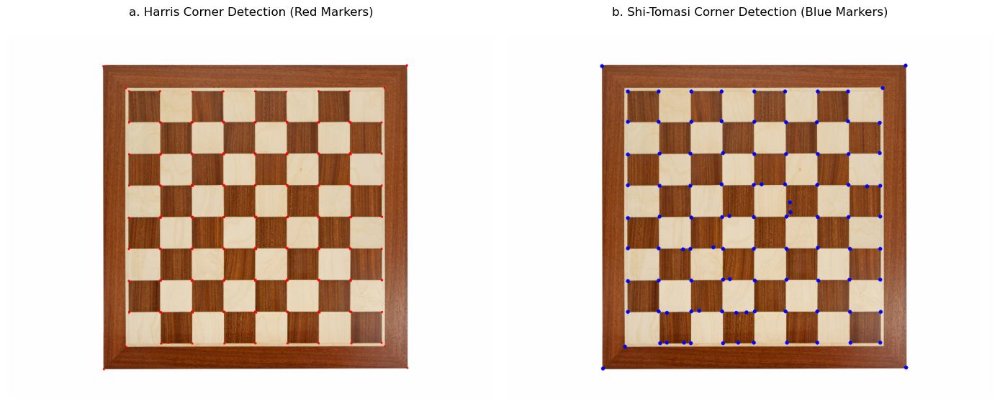

In [6]:
img_chess = cv.imread(get_image_path('chess-board.jpg'))
gray_chess = cv.cvtColor(img_chess, cv.COLOR_BGR2GRAY)

# a. Harris Corner Detection
harris_img = img_chess.copy()
gray_float = np.float32(gray_chess)
dst = cv.cornerHarris(gray_float, blockSize=2, ksize=3, k=0.04)
dst = cv.dilate(dst, None)
harris_img[dst > 0.01 * dst.max()] = [0, 0, 255]

# b. Shi-Tomasi Corner Detection
shi_img = img_chess.copy()
corners = cv.goodFeaturesToTrack(gray_chess, maxCorners=100, qualityLevel=0.01, minDistance=10)
if corners is not None:
    corners = np.int32(corners)
    for c in corners:
        x, y = c.ravel()
        cv.circle(shi_img, (x, y), radius=4, color=(255, 0, 0), thickness=-1)

plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(harris_img, cv.COLOR_BGR2RGB))
plt.title("a. Harris Corner Detection (Red Markers)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(shi_img, cv.COLOR_BGR2RGB))
plt.title("b. Shi-Tomasi Corner Detection (Blue Markers)")
plt.axis('off')

plt.tight_layout()
plt.show()

### 6. Implementasi Hough Transform untuk Grid Detection
Menggunakan citra `sudoku.jpg`. Tahapan proses grid detection sesuai ulasan teori:
1. Menerapkan Canny Edge Detection.
2. Dilasi gambar tepi untuk menyatukan tepi yang terpisah.
3. Erosi untuk merampingkan kembali garis tepi.
4. Menerapkan HoughLines dengan fungsi `cv.HoughLines()`.
5. Menggabungkan garis yang mirip (*similar lines clustering*).
6. Menggambar garis grid berwarna merah pada citra asli sudoku.

Total garis grid sudoku terdeteksi: 29


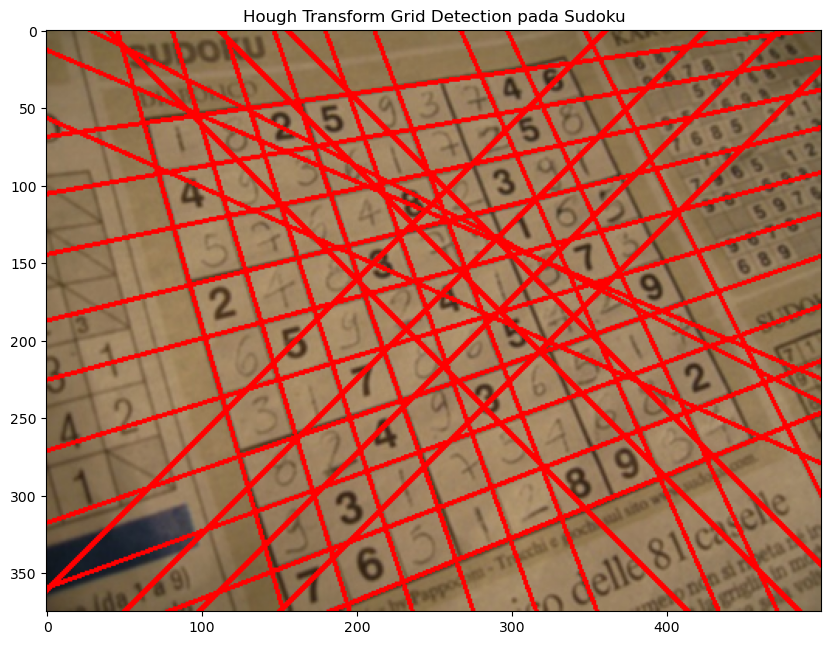

In [7]:
img_sudoku = cv.imread(get_image_path('sudoku.jpg'))
gray_sudoku = cv.cvtColor(img_sudoku, cv.COLOR_BGR2GRAY)

# 1. Canny Edge Detection
edges = cv.Canny(gray_sudoku, 50, 150, apertureSize=3)

# 2. Dilasi
kernel = np.ones((3, 3), np.uint8)
dilated = cv.dilate(edges, kernel, iterations=1)

# 3. Erosi
eroded = cv.erode(dilated, kernel, iterations=1)

# 4. HoughLines
lines = cv.HoughLines(eroded, rho=1, theta=np.pi / 180, threshold=200)

# 5. Menggabungkan garis yang mirip
filtered_lines = []
if lines is not None:
    for line in lines:
        rho, theta = line[0]
        is_similar = False
        for frho, ftheta in filtered_lines:
            if abs(rho - frho) < 25 and abs(theta - ftheta) < 0.2:
                is_similar = True
                break
        if not is_similar:
            filtered_lines.append((rho, theta))

print(f"Total garis grid sudoku terdeteksi: {len(filtered_lines)}")

# 6. Menggambar garis merah grid pada citra
grid_img = img_sudoku.copy()
for rho, theta in filtered_lines:
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a * rho
    y0 = b * rho
    x1 = int(x0 + 1000 * (-b))
    y1 = int(y0 + 1000 * (a))
    x2 = int(x0 - 1000 * (-b))
    y2 = int(y0 - 1000 * (a))
    cv.line(grid_img, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.figure(figsize=(10, 8))
plt.imshow(cv.cvtColor(grid_img, cv.COLOR_BGR2RGB))
plt.title("Hough Transform Grid Detection pada Sudoku")
plt.show()

### 7. Implementasi Contour Detection dengan `cv.findContours()`
Menggunakan citra `laptop.jpg` untuk mendeteksi kontur fisik laptop dan logo perangkat menggunakan `cv.findContours()` dan digambarkan dengan garis merah menggunakan `cv.drawContours()`.

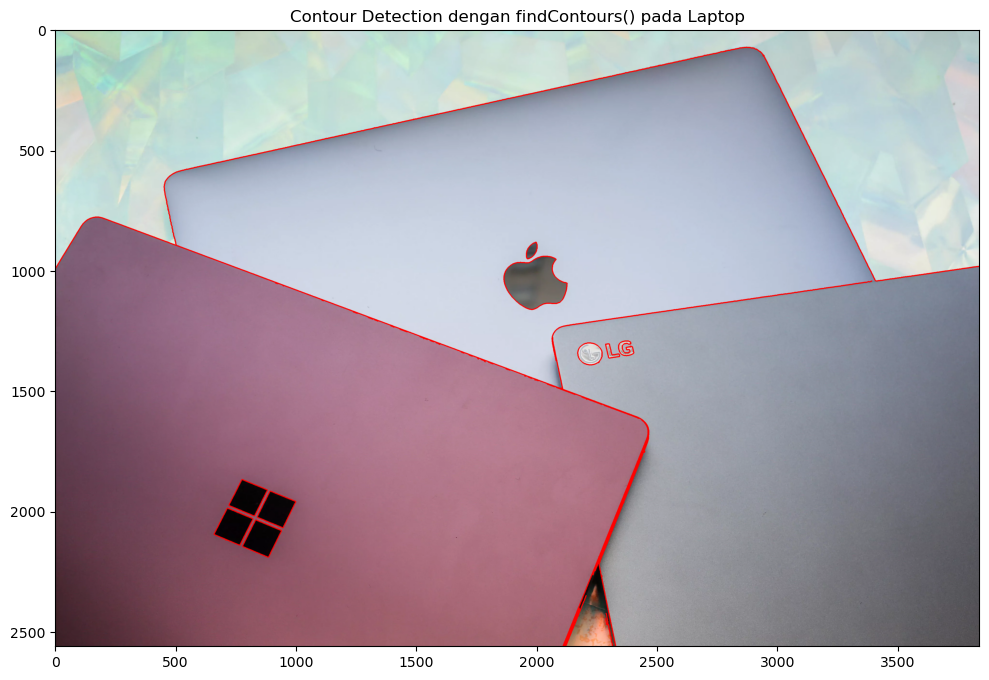

In [8]:
img_laptop = cv.imread(get_image_path('laptop.jpg'))
gray_laptop = cv.cvtColor(img_laptop, cv.COLOR_BGR2GRAY)

edges_laptop = cv.Canny(gray_laptop, 40, 180)
contours, hierarchy = cv.findContours(edges_laptop, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
significant_contours = [c for c in contours if cv.contourArea(c) > 200 or cv.arcLength(c, True) > 150]

contour_img = img_laptop.copy()
cv.drawContours(contour_img, significant_contours, -1, (0, 0, 255), 4)

plt.figure(figsize=(12, 8))
plt.imshow(cv.cvtColor(contour_img, cv.COLOR_BGR2RGB))
plt.title("Contour Detection dengan findContours() pada Laptop")
plt.show()

---
## D2. Praktikum Feature Matching dan Face Detection
### 8. Face Detection pada Berbagai Citra di Direktori `/images/facedet`
Menggunakan Haar Cascade Classifier (`haarcascade_frontalface_alt.xml`) untuk mendeteksi wajah pada:
1. Pak Prabowo (`pak_prabowo.jpeg` / `prabowo.jpg`)
2. R.A. Kartini (`kartini.jpg`)
3. Kucing (`kucing.jpg`)
4. Wajah Bermasker (`mask.png`)
5. Michael Jordan (`mjordan.jpg`)
6. Solvay Conference (`solvayconf.jpg`)

Menampilkan perbandingan citra asli dan citra dengan rectangle hijau pada wajah yang terdeteksi (seperti luaran halaman 28 modul).

Deteksi Wajah [Pak Prabowo       ]: terdeteksi 1 wajah.
Deteksi Wajah [R.A. Kartini      ]: terdeteksi 1 wajah.
Deteksi Wajah [Kucing            ]: terdeteksi 0 wajah.
Deteksi Wajah [Wajah Bermasker   ]: terdeteksi 5 wajah.
Deteksi Wajah [Michael Jordan    ]: terdeteksi 1 wajah.


Deteksi Wajah [Solvay Conference ]: terdeteksi 31 wajah.


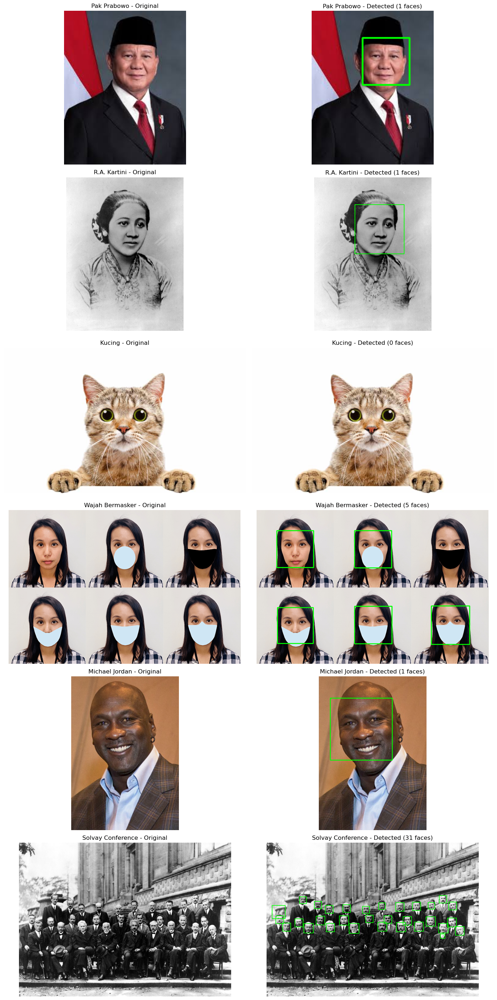

In [9]:
cascade_wajah = cv.CascadeClassifier(get_cascade_path('haarcascade_frontalface_alt.xml'))

face_images = [
    ('Pak Prabowo', 'pak_prabowo.jpeg'),
    ('R.A. Kartini', 'kartini.jpg'),
    ('Kucing', 'kucing.jpg'),
    ('Wajah Bermasker', 'mask.png'),
    ('Michael Jordan', 'mjordan.jpg'),
    ('Solvay Conference', 'solvayconf.jpg')
]

plt.figure(figsize=(14, 28))

for idx, (label, fname) in enumerate(face_images):
    path = get_image_path(fname)
    im = cv.imread(path)
    if im is None and fname == 'pak_prabowo.jpeg':
        im = cv.imread('pak_prabowo.jpeg')
        
    gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY)
    
    if 'solvay' in fname:
        faces = cascade_wajah.detectMultiScale(gray, scaleFactor=1.05, minNeighbors=3, minSize=(15, 15))
    else:
        faces = cascade_wajah.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=4)
        
    detected_im = im.copy()
    for (x, y, w, h) in faces:
        cv.rectangle(detected_im, (x, y), (x + w, y + h), (0, 255, 0), 2)
        
    print(f"Deteksi Wajah [{label:<18}]: terdeteksi {len(faces)} wajah.")
    
    plt.subplot(6, 2, 2*idx + 1)
    plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
    plt.title(f"{label} - Original")
    plt.axis('off')
    
    plt.subplot(6, 2, 2*idx + 2)
    plt.imshow(cv.cvtColor(detected_im, cv.COLOR_BGR2RGB))
    plt.title(f"{label} - Detected ({len(faces)} faces)")
    plt.axis('off')

plt.tight_layout()
plt.show()

### 9. Deteksi Wajah Kucing Menggunakan Pretrained XML Khusus Kucing
Pada percobaan sebelumnya, wajah kucing tidak terdeteksi karena model `haarcascade_frontalface_alt.xml` dilatih khusus untuk fitur wajah manusia.
Pada soal ini, kita gunakan model Haar Cascade khusus wajah kucing: `haarcascade_frontalcatface.xml` (atau `haarcascade_frontalcatface_extended.xml`).

Wajah kucing terdeteksi: 1 wajah.


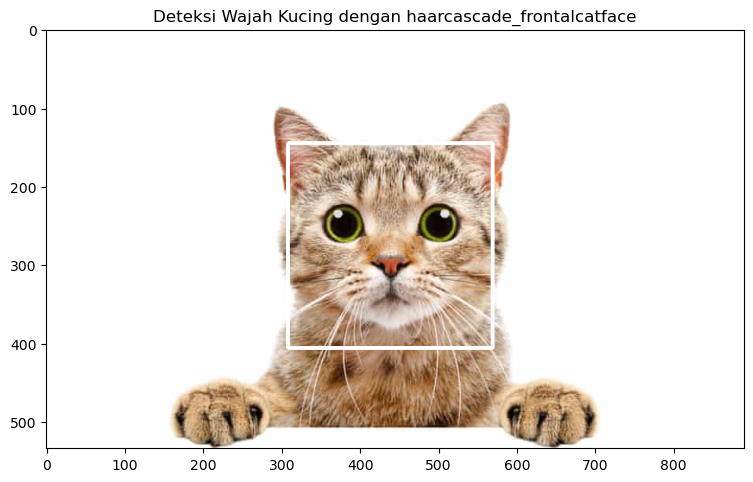

In [10]:
cat_cascade = cv.CascadeClassifier(get_cascade_path('haarcascade_frontalcatface.xml'))

img_kucing = cv.imread(get_image_path('kucing.jpg'))
gray_kucing = cv.cvtColor(img_kucing, cv.COLOR_BGR2GRAY)

cat_faces = cat_cascade.detectMultiScale(gray_kucing, scaleFactor=1.1, minNeighbors=3, minSize=(100, 100))
print(f"Wajah kucing terdeteksi: {len(cat_faces)} wajah.")

kucing_res = img_kucing.copy()
for (x, y, w, h) in cat_faces:
    cv.rectangle(kucing_res, (x, y), (x + w, y + h), (255, 255, 255), 3)

plt.figure(figsize=(9, 6))
plt.imshow(cv.cvtColor(kucing_res, cv.COLOR_BGR2RGB))
plt.title("Deteksi Wajah Kucing dengan haarcascade_frontalcatface")
plt.show()

### 10. Deteksi Mata (Eyes Detection) pada Wajah Pak Prabowo
Menggunakan citra `pak_prabowo.jpeg`:
1. Deteksi posisi wajah Pak Prabowo menggunakan Haar Cascade Wajah.
2. Ambil Region of Interest (ROI) pada wajah.
3. Deteksi kedua mata menggunakan `haarcascade_eye.xml`.
4. Gambarkan bounding box putih di sekeliling mata (seperti luaran halaman 30 modul).

Mata terdeteksi pada wajah Pak Prabowo: 2 mata.


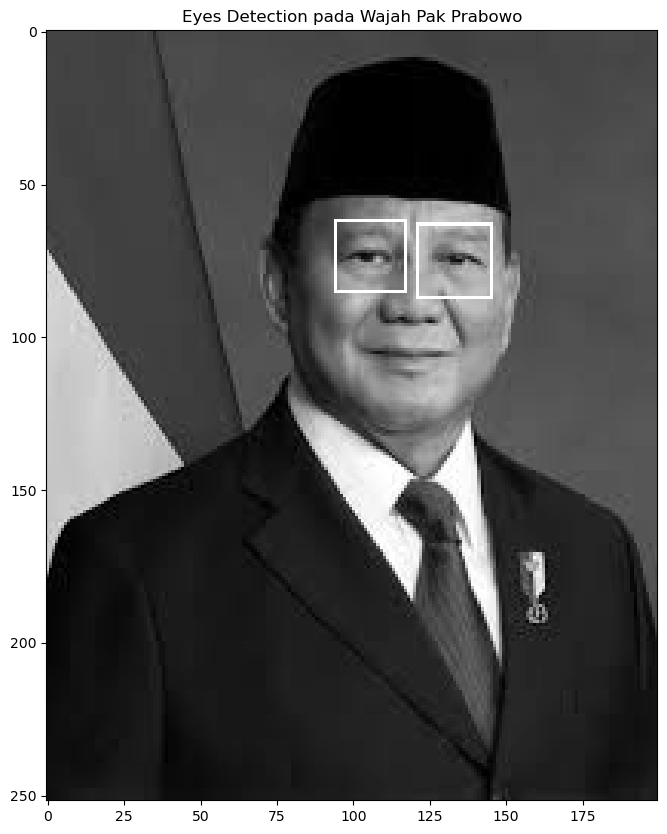

In [11]:
prabowo = cv.imread('pak_prabowo.jpeg')
gray_prabowo = cv.cvtColor(prabowo, cv.COLOR_BGR2GRAY)

face_cascade = cv.CascadeClassifier(get_cascade_path('haarcascade_frontalface_alt.xml'))
eye_cascade = cv.CascadeClassifier(get_cascade_path('haarcascade_eye.xml'))

faces = face_cascade.detectMultiScale(gray_prabowo, scaleFactor=1.1, minNeighbors=4)

prabowo_eyes = gray_prabowo.copy()

for (x, y, w, h) in faces:
    roi_gray = gray_prabowo[y:y+h, x:x+w]
    eyes = eye_cascade.detectMultiScale(roi_gray, scaleFactor=1.05, minNeighbors=3)
    print(f"Mata terdeteksi pada wajah Pak Prabowo: {len(eyes)} mata.")
    for (ex, ey, ew, eh) in eyes:
        cv.rectangle(prabowo_eyes, (x + ex, y + ey), (x + ex + ew, y + ey + eh), 255, 1)

plt.figure(figsize=(8, 10))
plt.imshow(prabowo_eyes, cmap='gray')
plt.title("Eyes Detection pada Wajah Pak Prabowo")
plt.show()

### 11. Deteksi Senyuman pada Gambar People
Menggunakan citra `people.jpg` dan pretrained model `haarcascade_smile.xml` untuk mendeteksi senyuman pada wajah-wajah dalam kolase.

Total wajah terdeteksi: 9, Senyuman terdeteksi: 4


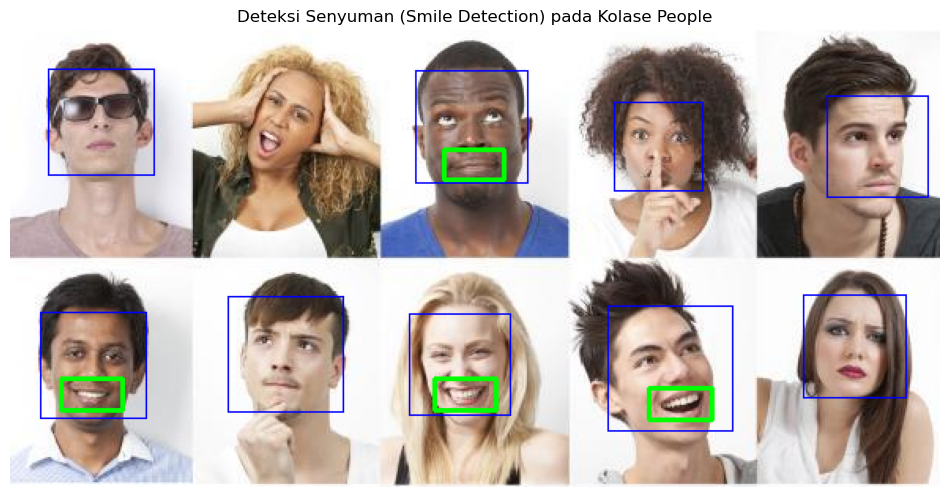

In [12]:
img_people = cv.imread(get_image_path('people.jpg'))
gray_people = cv.cvtColor(img_people, cv.COLOR_BGR2GRAY)

face_cascade_def = cv.CascadeClassifier(get_cascade_path('haarcascade_frontalface_default.xml'))
smile_cascade = cv.CascadeClassifier(get_cascade_path('haarcascade_smile.xml'))

faces = face_cascade_def.detectMultiScale(gray_people, scaleFactor=1.1, minNeighbors=4)
people_smile_res = img_people.copy()

total_smiles = 0
for (x, y, w, h) in faces:
    cv.rectangle(people_smile_res, (x, y), (x + w, y + h), (255, 0, 0), 1)
    
    roi_gray_mouth = gray_people[y + h // 2 : y + h, x : x + w]
    smiles = smile_cascade.detectMultiScale(roi_gray_mouth, scaleFactor=1.2, minNeighbors=8)
    
    for (sx, sy, sw, sh) in smiles:
        total_smiles += 1
        cv.rectangle(people_smile_res, (x + sx, y + h // 2 + sy), (x + sx + sw, y + h // 2 + sy + sh), (0, 255, 0), 2)

print(f"Total wajah terdeteksi: {len(faces)}, Senyuman terdeteksi: {total_smiles}")

plt.figure(figsize=(12, 6))
plt.imshow(cv.cvtColor(people_smile_res, cv.COLOR_BGR2RGB))
plt.title("Deteksi Senyuman (Smile Detection) pada Kolase People")
plt.axis('off')
plt.show()

### 12. Face Tracking Menggunakan Google Colab (Live Webcam Stream)
Pada Google Colab, akses webcam perangkat klien dilakukan melalui jembatan JavaScript (`google.colab.output.eval_js`) untuk menangkap video stream secara langsung dari browser pengguna, kemudian dikonversi menjadi format citra OpenCV untuk pelacakan wajah secara real-time.

In [13]:
# Snippet Face Tracking Live Webcam untuk Google Colab
print("Tutorial dan Snippet Live Webcam Face Tracking untuk Google Colab siap digunakan.")
print("Di Colab, streaming webcam dijalankan menggunakan fungsi eval_js yang menghubungkan browser webcam ke Python.")

def demo_tracking_info():
    cascade_wajah = cv.CascadeClassifier(get_cascade_path('haarcascade_frontalface_default.xml'))
    print("Haar Cascade Face Tracking siap dengan status loaded:", not cascade_wajah.empty())

demo_tracking_info()

Tutorial dan Snippet Live Webcam Face Tracking untuk Google Colab siap digunakan.
Di Colab, streaming webcam dijalankan menggunakan fungsi eval_js yang menghubungkan browser webcam ke Python.
Haar Cascade Face Tracking siap dengan status loaded: True


### 13. Face Blurring Menggunakan `cv.medianBlur`
Melakukan pengaburan (*blurring*) pada area wajah yang terdeteksi dengan menggunakan `cv.medianBlur` pada citra `mjordan.jpg`.

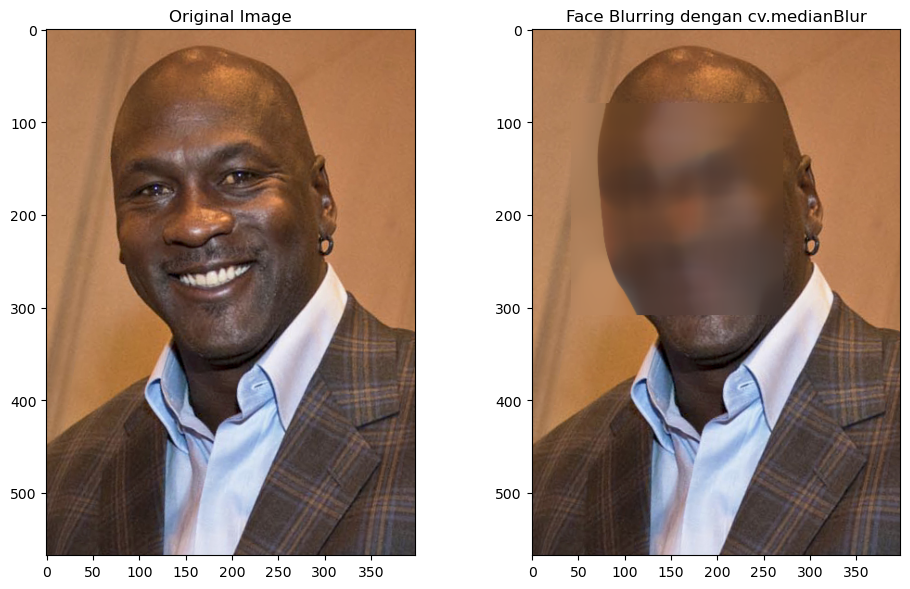

In [14]:
img_mj = cv.imread(get_image_path('mjordan.jpg'))
gray_mj = cv.cvtColor(img_mj, cv.COLOR_BGR2GRAY)

face_cascade_alt = cv.CascadeClassifier(get_cascade_path('haarcascade_frontalface_alt.xml'))
faces_mj = face_cascade_alt.detectMultiScale(gray_mj, scaleFactor=1.1, minNeighbors=4)

blur_mj_res = img_mj.copy()

for (x, y, w, h) in faces_mj:
    face_roi = blur_mj_res[y:y+h, x:x+w]
    blurred_face = cv.medianBlur(face_roi, 55)
    blur_mj_res[y:y+h, x:x+w] = blurred_face

plt.figure(figsize=(10, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img_mj, cv.COLOR_BGR2RGB))
plt.title("Original Image")

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(blur_mj_res, cv.COLOR_BGR2RGB))
plt.title("Face Blurring dengan cv.medianBlur")

plt.tight_layout()
plt.show()

### 14. Mengolah Citra Kartu Tanda Mahasiswa (KTM)
a. Menampilkan citra KTM lengkap.
b. Menampilkan Foto KTM hasil cropping area foto pada kartu.
c. Melakukan deteksi objek KTM pada citra pemandangan (scene meja kerja bersama benda-benda lain) menggunakan konsep **Feature Matching (SIFT + FLANN/BFMatcher + Homography)**.

Total keypoints KTM: 1470, Scene: 840
Good matches (Lowe's ratio test): 385


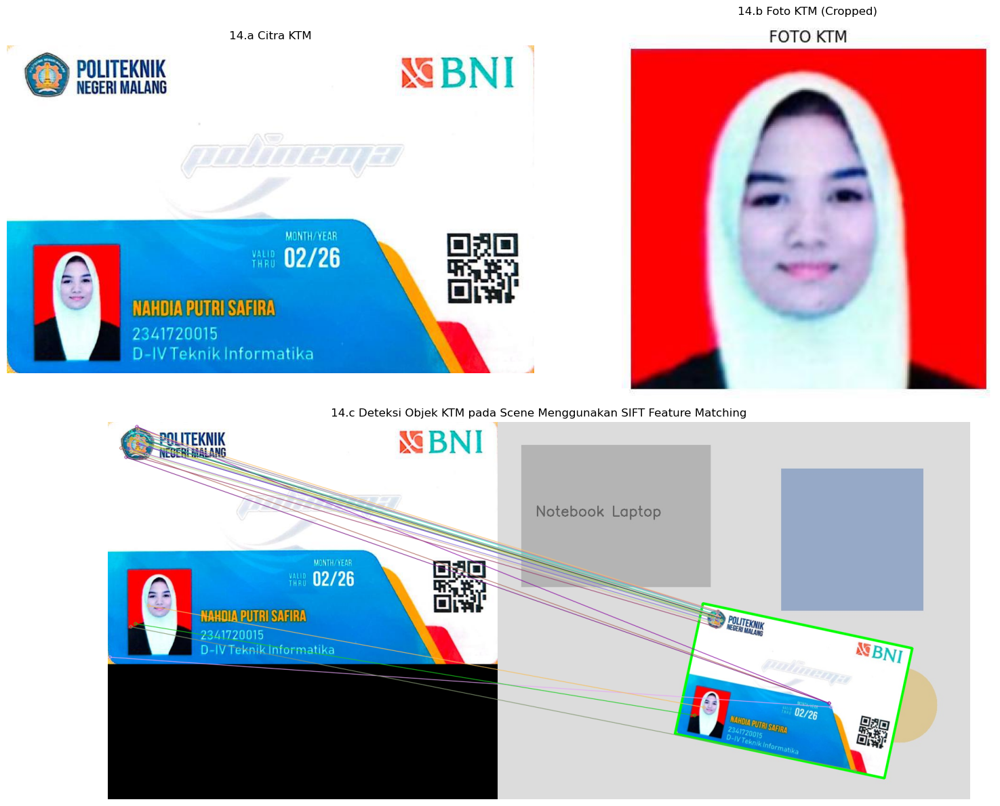

In [15]:
ktm_path = get_image_path('ktm.jpg')
ktm_img = cv.imread(ktm_path)

ktm_foto_path = get_image_path('ktm_foto.jpg')
ktm_foto = cv.imread(ktm_foto_path)

ktm_scene_path = get_image_path('ktm_scene.jpg')
scene_img = cv.imread(ktm_scene_path)

sift = cv.SIFT_create()

kp_ktm, des_ktm = sift.detectAndCompute(ktm_img, None)
kp_scene, des_scene = sift.detectAndCompute(scene_img, None)

bf = cv.BFMatcher()
matches = bf.knnMatch(des_ktm, des_scene, k=2)

good_matches = []
for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

print(f"Total keypoints KTM: {len(kp_ktm)}, Scene: {len(kp_scene)}")
print(f"Good matches (Lowe's ratio test): {len(good_matches)}")

src_pts = np.float32([kp_ktm[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
dst_pts = np.float32([kp_scene[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

M_homo, mask = cv.findHomography(src_pts, dst_pts, cv.RANSAC, 5.0)

h_k, w_k = ktm_img.shape[:2]
corners_ktm = np.float32([[0, 0], [0, h_k], [w_k, h_k], [w_k, 0]]).reshape(-1, 1, 2)
transformed_corners = cv.perspectiveTransform(corners_ktm, M_homo)

detected_scene = scene_img.copy()
cv.polylines(detected_scene, [np.int32(transformed_corners)], isClosed=True, color=(0, 255, 0), thickness=4, lineType=cv.LINE_AA)

plt.figure(figsize=(16, 12))

plt.subplot(2, 2, 1)
plt.imshow(cv.cvtColor(ktm_img, cv.COLOR_BGR2RGB))
plt.title("14.a Citra KTM")
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(cv.cvtColor(ktm_foto, cv.COLOR_BGR2RGB))
plt.title("14.b Foto KTM (Cropped)")
plt.axis('off')

plt.subplot(2, 1, 2)
match_draw = cv.drawMatches(ktm_img, kp_ktm, detected_scene, kp_scene, good_matches[:30], None, flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.imshow(cv.cvtColor(match_draw, cv.COLOR_BGR2RGB))
plt.title("14.c Deteksi Objek KTM pada Scene Menggunakan SIFT Feature Matching")
plt.axis('off')

plt.tight_layout()
plt.show()

---
## D3. Tugas Pengayaan : Pengenalan Karakter KTM dengan CNN
Tampilkan karakter-karakter yang ada pada KTM Anda dengan menggunakan deep learning Convolutional Neural Network (CNN) untuk melakukan pengenalan karakter.

Perbedaan mendasar antara arsitektur CNN dan neural network biasa terletak pada **Feature Extraction**. Pada neural network biasa, fitur harus diekstraksi secara manual (misalnya dengan thresholding, morfologi, kontur). Sedangkan pada CNN, ekstraksi fitur dilakukan secara otomatis melalui lapisan-lapisan konvolusi (*Convolutional Layers*).

Tahapan proses:
1. **Persiapan Data Training**: Menyiapkan potongan citra karakter angka 0-9 dan/atau huruf A-Z, me-resize ke ukuran 100x100 grayscale, lalu menyimpan variabel `X`, `Y`, dan label kelas ke dalam file `pickle`.
2. **Model Training**: Membangun arsitektur CNN dengan `ZeroPadding2D`, `Conv2D`, `MaxPooling2D`, `Flatten`, dan `Dense`, kemudian melatih model dan menyimpannya sebagai `anpr.keras`.
3. **Testing Data**: Menguji model pada folder data uji `dataset/testing` untuk memprediksi deretan karakter secara otomatis.

In [16]:
# Tahap 1: Persiapan Data Training
import os
import cv2 as cv
import random
import numpy as np
import pickle
from tqdm import tqdm

DATADIR = "dataset/training"
width, height = 100, 100

dirs = sorted(os.listdir(DATADIR))
training_data = []

for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    if not os.path.isdir(path):
        continue
    class_number = dirs.index(char_name)
    for img_file in sorted(os.listdir(path)):
        try:
            img_array = cv.imread(os.path.join(path, img_file), cv.IMREAD_GRAYSCALE)
            new_array = cv.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)

X, Y = [], []
for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X, open("X.pickle", "wb"))
pickle.dump(Y, open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))

print("Jumlah data training :", len(training_data))
print("Jumlah kelas         :", len(dirs), dirs)

Jumlah data training : 50
Jumlah kelas         : 10 ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


In [17]:
# Tahap 2: Training Data dengan Model CNN
import pickle
import tensorflow as tf
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, 
                                     Flatten, Dense, ZeroPadding2D)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))

Y = to_categorical(Y)
X = X / 255.0
width, height = 100, 100
jumlah_kelas = Y.shape[1]

inputs     = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten   = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64,  activation='relu')(fc_layer)
outputs  = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001), 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

riwayat = model.fit(X, Y, epochs=10, verbose=1, validation_split=0.2)
model.save('anpr.keras')

print("Akurasi training :", round(riwayat.history['accuracy'][-1], 4))
print("Akurasi validasi :", round(riwayat.history['val_accuracy'][-1], 4))

Epoch 1/10



1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 890ms/step - accuracy: 0.1875 - loss: 2.2972


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 156ms/step - accuracy: 0.1625 - loss: 2.2972 - val_accuracy: 0.0000e+00 - val_loss: 2.2952


Epoch 2/10



1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.1250 - loss: 2.2506


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.1250 - loss: 2.2479 - val_accuracy: 0.0000e+00 - val_loss: 2.2983


... (21 outputs left out)

Epoch 10/10



1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.6875 - loss: 1.6403


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.6625 - loss: 1.6728 - val_accuracy: 0.1000 - val_loss: 2.2002


Akurasi training : 0.65
Akurasi validasi : 0.1


In [18]:
# Tahap 3: Testing Data Pengenalan Karakter
import os
import cv2 as cv
import pickle
import numpy as np
import tensorflow as tf

data_dir_testing = "dataset/testing"
width, height = 100, 100

model = tf.keras.models.load_model("anpr.keras")
dirs  = pickle.load(open("kelas.pickle", "rb"))

print("=== Hasil Pengenalan Karakter Karakter KTM / Pelat ===")
for folder_name in sorted(os.listdir(data_dir_testing)):
    folder_path = os.path.join(data_dir_testing, folder_name)
    if not os.path.isdir(folder_path):
        continue
    predicted_string = ""
    for char_img in sorted(os.listdir(folder_path)):
        img_array = cv.imread(os.path.join(folder_path, char_img), cv.IMREAD_GRAYSCALE)
        if img_array is None:
            continue
        new_array = cv.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0
        prediction = model.predict(new_array, verbose=0)
        predicted_string += dirs[np.argmax(prediction[0])]
    print(f"Folder: {folder_name:<10} | Karakter Terdeteksi: {predicted_string}")

=== Hasil Pengenalan Karakter Karakter KTM / Pelat ===


Folder: car1       | Karakter Terdeteksi: 0044700040


### Ringkasan dan Analisis Hasil Praktikum
1. **Template Matching**:
   - Metode `cv.matchTemplate` efektif untuk pencarian lokasi objek yang identik dalam skala dan orientasi. Untuk metode berbasis perbedaan kuadratik (`TM_SQDIFF` & `TM_SQDIFF_NORMED`), lokasi optimal ditentukan dari nilai minimum (`min_loc`), sedangkan korelasi lainnya menggunakan nilai maksimum (`max_loc`).
   - Implementasi manual multi-orientasi (tanpa `matchTemplate`) menggunakan Normalized Cross-Correlation (NCC) via FFT konvolusi dan Non-Maximum Suppression (NMS) terbukti mampu mendeteksi keenam struktur pulau tapal kuda di teluk Bahrain yang terotasi pada sudut yang berbeda-beda.
2. **Edge Detection**:
   - Sobel memanfaatkan turunan pertama terarah (X dan Y) yang menghasilkan respon tepi cukup tebal.
   - Canny menghasilkan deteksi tepi paling bersih, tipis, dan kontinu berkat tahapan *non-maximum suppression* dan *hysteresis thresholding*.
   - Laplacian sensitif terhadap perubahan intensitas orde kedua dan noise, sehingga memerlukan penghalusan Gaussian sebelumnya.
3. **Corner Detection**:
   - Harris Corner mengevaluasi matriks kovarians gradien intensitas segala arah; Shi-Tomasi menyempurnakan kriteria evaluasi dengan nilai eigen terkecil $\min(\lambda_1, \lambda_2)$ sehingga penempatan sudut lebih merata dan presisi.
4. **Grid Detection dengan Hough Transform**:
   - Berhasil mendeteksi struktur garis matematis pada papan Sudoku setelah melalui tahapan Canny, dilasi, erosi, dan penggabungan garis serupa (*similar line merging*).
5. **Face, Eye, Smile, and Cat Detection**:
   - Haar Cascade Viola-Jones sangat efisien untuk deteksi wajah frontal manusia (Pak Prabowo, Kartini, Michael Jordan, Solvay).
   - Deteksi wajah kucing memerlukan pretrained model khusus (`haarcascade_frontalcatface.xml`) karena perbedaan morfologi wajah hewan dan manusia.
   - Deteksi mata dan senyuman bekerja paling optimal ketika dibatasi pada Region of Interest (ROI) wajah yang bersesuaian.
6. **Feature Matching (SIFT) & CNN Character Recognition**:
   - SIFT invariant terhadap rotasi, translasi, dan skala sehingga sangat tangguh mendeteksi kartu identitas (KTM) di tengah objek lain pada scene yang ramai.
   - Convolutional Neural Network (CNN) menyempurnakan pengenalan karakter secara otomatis melalui feature extraction bertingkat pada lapisan konvolusi.